In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import kagglehub
import numpy as np
#from pycaret.classification import setup, compare_models, create_model, tune_model, finalize_model, predict_model
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score, auc, roc_curve, confusion_matrix
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.utils.class_weight import compute_sample_weight, compute_class_weight
from xgboost import XGBClassifier
from sklearn.ensemble import AdaBoostClassifier
import lightgbm as lgb

/home/orlandojunior/miniconda3/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Download latest version
path = kagglehub.competition_download('playground-series-s6e11')

print("Path to competition files:", path)

Path to competition files: /home/orlandojunior/.cache/kagglehub/competitions/playground-series-s6e11


In [3]:
df_train = pd.read_csv(f"{path}/train.csv")
df_test = pd.read_csv(f"{path}/test.csv")

In [4]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Data columns (total 26 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   id                            699960 non-null  int64  
 1   amount_usd                    699960 non-null  float64
 2   hours_since_last_txn          699960 non-null  float64
 3   txn_count_last_24h            699960 non-null  int64  
 4   distance_from_home_km         699960 non-null  float64
 5   card_age_months               699960 non-null  int64  
 6   customer_age                  699960 non-null  int64  
 7   account_balance_usd           699960 non-null  float64
 8   cvv_retry_count               699960 non-null  int64  
 9   velocity_score                699960 non-null  float64
 10  time_of_day_hour              699960 non-null  int64  
 11  day_of_week                   699960 non-null  int64  
 12  merchant_risk_score           699960 non-null  float64


In [5]:
df_train.head()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,...,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,...,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,...,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,...,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,...,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


In [6]:
# best = compare_models(sort='AUC',fold=3)

In [7]:
# print(ada)

In [8]:
def transform_data(df_1: pd.DataFrame, df_2: pd.DataFrame):
    
    ids = df_2['id']
    df_1 = df_1.drop(columns=['id'])
    df_2 = df_2.drop(columns=['id'])
    
    features_bool = df_1.select_dtypes(include=['bool']).columns
    
    for col in features_bool:
        df_1[col] = df_1[col].apply(lambda x: 1 if x == True else 0)
        df_2[col] = df_2[col].apply(lambda x: 1 if x == True else 0)
    
    df = pd.concat([df_1,df_2], axis=0)
    
    return ids, df

ids, df = transform_data(df_train,df_test)

In [9]:
df.info()

<class 'pandas.DataFrame'>
Index: 999944 entries, 0 to 299983
Data columns (total 25 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   amount_usd                    999944 non-null  float64
 1   hours_since_last_txn          999944 non-null  float64
 2   txn_count_last_24h            999944 non-null  int64  
 3   distance_from_home_km         999944 non-null  float64
 4   card_age_months               999944 non-null  int64  
 5   customer_age                  999944 non-null  int64  
 6   account_balance_usd           999944 non-null  float64
 7   cvv_retry_count               999944 non-null  int64  
 8   velocity_score                999944 non-null  float64
 9   time_of_day_hour              999944 non-null  int64  
 10  day_of_week                   999944 non-null  int64  
 11  merchant_risk_score           999944 non-null  float64
 12  prior_disputes                999944 non-null  int64  
 13  

In [10]:
features_to_scaler = df.select_dtypes(include=['number']).columns
features_to_one_hot = df.select_dtypes(include=['str']).columns

In [11]:
features_to_scaler = ['amount_usd', 'hours_since_last_txn', 'txn_count_last_24h',
       'distance_from_home_km', 'card_age_months', 'customer_age',
       'account_balance_usd', 'cvv_retry_count', 'velocity_score',
       'time_of_day_hour', 'day_of_week', 'merchant_risk_score',
       'prior_disputes', 'is_foreign_transaction', 'is_new_merchant',
       'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch',
       'is_ai_generated_scam_attempt']

In [12]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num',StandardScaler(), features_to_scaler),
        ('cat', OneHotEncoder(handle_unknown='ignore',sparse_output=False), features_to_one_hot)
    ],
    remainder='passthrough'
)

new_df = preprocessor.fit_transform(df)
names = preprocessor.get_feature_names_out()

new_data_frame = pd.DataFrame(data=new_df,columns=names)
new_data_frame.head()

,num__amount_usd,num__hours_since_last_txn,num__txn_count_last_24h,num__distance_from_home_km,num__card_age_months,num__customer_age,num__account_balance_usd,num__cvv_retry_count,num__velocity_score,num__time_of_day_hour,...,cat__channel_POS,cat__device_type_ATM Machine,cat__device_type_Android Phone,cat__device_type_Mac,cat__device_type_POS Terminal,cat__device_type_Smart Watch,cat__device_type_Tablet,cat__device_type_Windows PC,cat__device_type_iPhone,remainder__is_fraud
0,-0.091788,0.497909,-1.323864,0.360545,0.204879,0.255436,-0.233957,-0.29524,-1.236175,0.763141,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,-0.269716,-0.809496,0.010672,-0.045816,-1.586508,-1.309079,0.342041,-0.29524,1.331491,1.636536,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,-0.360174,-0.863508,0.677940,-0.466813,0.563156,0.199561,-0.299215,-0.29524,1.552366,0.472009,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,-0.207958,-0.239195,0.677940,-0.423766,0.204879,-0.191568,0.044214,-0.29524,0.162697,-0.692519,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2.810950,-0.927051,0.677940,-0.163764,-1.765646,0.031934,0.359072,-0.29524,1.460335,-1.129217,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


In [13]:
df_training = new_data_frame[:len(df_train)]
df_testing = new_data_frame[len(df_train):]

df_testing.info()

<class 'pandas.DataFrame'>
RangeIndex: 299984 entries, 699960 to 999943
Data columns (total 55 columns):
 #   Column                                  Non-Null Count   Dtype  
---  ------                                  --------------   -----  
 0   num__amount_usd                         299984 non-null  float64
 1   num__hours_since_last_txn               299984 non-null  float64
 2   num__txn_count_last_24h                 299984 non-null  float64
 3   num__distance_from_home_km              299984 non-null  float64
 4   num__card_age_months                    299984 non-null  float64
 5   num__customer_age                       299984 non-null  float64
 6   num__account_balance_usd                299984 non-null  float64
 7   num__cvv_retry_count                    299984 non-null  float64
 8   num__velocity_score                     299984 non-null  float64
 9   num__time_of_day_hour                   299984 non-null  float64
 10  num__day_of_week                        299984 non

In [14]:
df_testing = df_testing.drop(columns=['remainder__is_fraud'])
df_testing.info()

<class 'pandas.DataFrame'>
RangeIndex: 299984 entries, 699960 to 999943
Data columns (total 54 columns):
 #   Column                                  Non-Null Count   Dtype  
---  ------                                  --------------   -----  
 0   num__amount_usd                         299984 non-null  float64
 1   num__hours_since_last_txn               299984 non-null  float64
 2   num__txn_count_last_24h                 299984 non-null  float64
 3   num__distance_from_home_km              299984 non-null  float64
 4   num__card_age_months                    299984 non-null  float64
 5   num__customer_age                       299984 non-null  float64
 6   num__account_balance_usd                299984 non-null  float64
 7   num__cvv_retry_count                    299984 non-null  float64
 8   num__velocity_score                     299984 non-null  float64
 9   num__time_of_day_hour                   299984 non-null  float64
 10  num__day_of_week                        299984 non

In [15]:
df_training.value_counts('remainder__is_fraud')

remainder__is_fraud
0.0    688271
1.0     11689
Name: count, dtype: int64

In [16]:
X = df_training.drop(columns=['remainder__is_fraud'])
y = df_training['remainder__is_fraud']

In [17]:

X_train, X_temp, y_train, y_temp = train_test_split(X,y,test_size=0.3, random_state=42, shuffle=True,stratify=y)
X_test, X_val, y_test, y_val = train_test_split(X_temp,y_temp,test_size=0.5, random_state=42, shuffle=True,stratify=y_temp)


# X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3, random_state=42, shuffle=True,stratify=y)

# sample_weights = compute_sample_weight(
#     class_weight='balanced',
#     y=y_train
# )


class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y),
    y=y
    
)

print(X_train.shape, X_test.shape)

(489972, 54) (104994, 54)


In [18]:
# xgb_clf = XGBClassifier(early_stopping_rounds=10)

# xgb_clf.fit(X_train, y_train,sample_weight = sample_weights,                  
#             eval_set = [(X_val,y_val)])


# ada_clf = AdaBoostClassifier()

# ada_clf.fit(X_train, y_train, sample_weight=sample_weights)

lgbm_clf = lgb.LGBMClassifier(
    class_weight='balanced'
)

lgbm_clf.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=True)]
)

/home/orlandojunior/miniconda3/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 8182, number of negative: 481790
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.011779 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1787
[LightGBM] [Info] Number of data points in the train set: 489972, number of used features: 54
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[100]	valid_0's binary_logloss: 0.265555


,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,class_weight,'balanced'
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [19]:
preds = lgbm_clf.predict(X_test)
y_pred_probs = lgbm_clf.predict_proba(X_test)[:,1]

In [20]:
print(classification_report(y_test,preds))

              precision    recall  f1-score   support

         0.0       1.00      0.88      0.94    103240
         1.0       0.11      0.85      0.20      1754

    accuracy                           0.88    104994
   macro avg       0.55      0.87      0.57    104994
weighted avg       0.98      0.88      0.92    104994



0.8691241958934182
0.9418843551044228


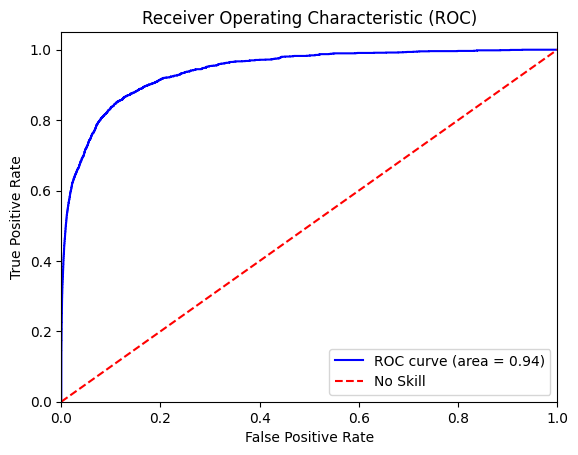

In [21]:
print(roc_auc_score(y_test,preds))

fpr, tpr, thresholds = roc_curve(y_test, y_pred_probs)
roc_auc = auc(fpr, tpr)
print(roc_auc)
plt.figure()
plt.plot(
    fpr, tpr, color='blue', label='ROC curve (area = %0.2f)' % roc_auc
)
plt.plot([0, 1], [0, 1], color='red', linestyle='--', label='No Skill')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc='lower right')
plt.show()

In [22]:
classes = np.unique(df_training['remainder__is_fraud'].astype('int'))
classes

array([0, 1])

<Axes: >

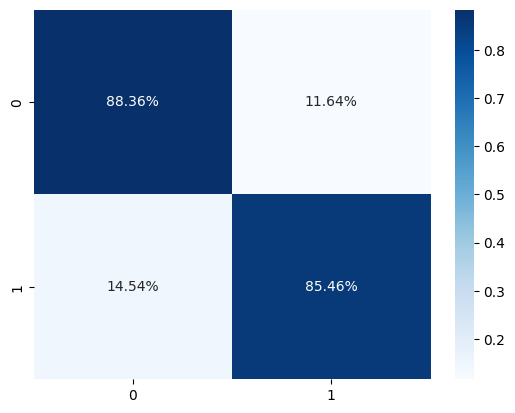

In [23]:
cm = confusion_matrix(y_test,preds, normalize="true")

sns.heatmap(
    cm,
    cmap="Blues",
    annot=True,
    fmt=".2%",
    xticklabels=classes,
    yticklabels=classes
)

In [24]:
preds_final = lgbm_clf.predict_proba(df_testing)[:,1]
df_final = pd.DataFrame({
    "id": ids,
    "is_fraud":preds_final
})

df_final.head()

,id,is_fraud
0,699960,0.008707
1,699961,0.009794
2,699962,0.875226
3,699963,0.069042
4,699964,0.069994


In [25]:
submission = df_final.to_csv("submission.csv",index=False)